# Naive FFT deconvolution

Saina Nikmehr — CS 163 ABR Deconvolution

I first test the FFT estimator on simulated EEG, where the response is known. I then use the same unregularized estimator on five Experiment 2 EEG recordings. The real-data estimates are exploratory and use one speech band.

## Fourier-domain estimate

For each trial, I use $y_i = x_i * h + n_i$, where $x_i$ is the pulse train, $h$ is the response and $n_i$ is noise. In the Fourier domain, $Y_i = X_iH + N_i$.

For one trial, direct division gives $\widehat H = Y/X$ when $X\neq 0$. For multiple trials, I combine the cross-spectra before dividing:

$$
\widehat H(f) = \frac{\sum_{i=1}^N X_i^*(f)Y_i(f)}{\sum_{i=1}^N |X_i(f)|^2}.
$$

This is an unregularized pooled estimate. Frequency bins with zero input power are set to zero because division there is undefined. The inverse FFT gives the estimated response in time.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import rfft, irfft, next_fast_len
from IPython.display import display


def naive_inverse(cross_spectrum, input_power, fft_length):
    H = np.zeros_like(cross_spectrum)
    np.divide(cross_spectrum, input_power, out=H, where=input_power > 0)
    return irfft(H, n=fft_length)

## 1. Check the estimator on simulated EEG

The pulse timings and noise vary by trial, but the response is the same. Because I know the response I used to generate the EEG, I can measure reconstruction error.

In [2]:
rng = np.random.default_rng(16)
fs = 2000
n_samples = 4096
n_trials = 64
response_length = 60

latency = np.arange(response_length) / fs
h_true = (
    0.18 * np.exp(-0.5 * ((latency - 0.0037) / 0.0007) ** 2)
    + 0.95 * np.exp(-0.5 * ((latency - 0.0070) / 0.0010) ** 2)
    - 0.52 * np.exp(-0.5 * ((latency - 0.0101) / 0.0012) ** 2)
)

pulses = np.zeros((n_trials, n_samples))
for i in range(n_trials):
    pos = int(rng.integers(20, 45))
    while pos < n_samples - 60:
        pulses[i, pos] = 1
        pos += int(rng.integers(16, 26))

clean_eeg = np.array([np.convolve(x, h_true, mode="full") for x in pulses])
eeg = clean_eeg + rng.normal(scale=1.0, size=clean_eeg.shape)

print(f"Simulated {n_trials} trials at {fs} Hz")

Simulated 64 trials at 2000 Hz


In [3]:
fft_size = next_fast_len(eeg.shape[1])
X = rfft(pulses, n=fft_size, axis=1)
Y = rfft(eeg, n=fft_size, axis=1)


def simulated_estimate(count):
    cross_spectrum = np.sum(np.conj(X[:count]) * Y[:count], axis=0)
    input_power = np.sum(np.abs(X[:count]) ** 2, axis=0)
    return naive_inverse(cross_spectrum, input_power, fft_size)[:response_length]


def rmse(estimate):
    return np.sqrt(np.mean((estimate - h_true) ** 2))


trial_counts = [1, 2, 4, 8, 16, 32, 64]
simulated = {n: simulated_estimate(n) for n in trial_counts}
scores = pd.DataFrame({
    "trials": trial_counts,
    "rmse": [rmse(simulated[n]) for n in trial_counts],
    "correlation": [np.corrcoef(h_true, simulated[n])[0, 1] for n in trial_counts]
})
display(scores.round(4))

,trials,rmse,correlation
0,1,0.2299,0.6871
1,2,0.0706,0.9626
2,4,0.0434,0.9862
3,8,0.0489,0.9812
4,16,0.0291,0.9934
5,32,0.0189,0.9973
6,64,0.0147,0.9984


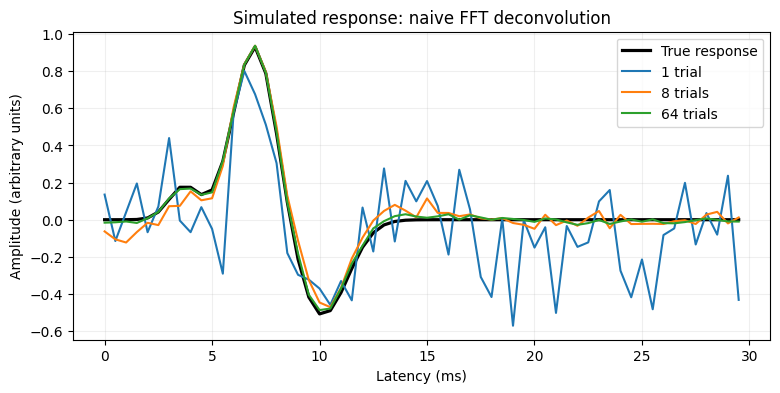

In [4]:
ms = latency * 1000
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ms, h_true, color="black", lw=2.3, label="True response")
for n in [1, 8, 64]:
    ax.plot(ms, simulated[n], label=f"{n} trial{'s' if n != 1 else ''}")
ax.set(xlabel="Latency (ms)", ylabel="Amplitude (arbitrary units)",
       title="Simulated response: naive FFT deconvolution")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

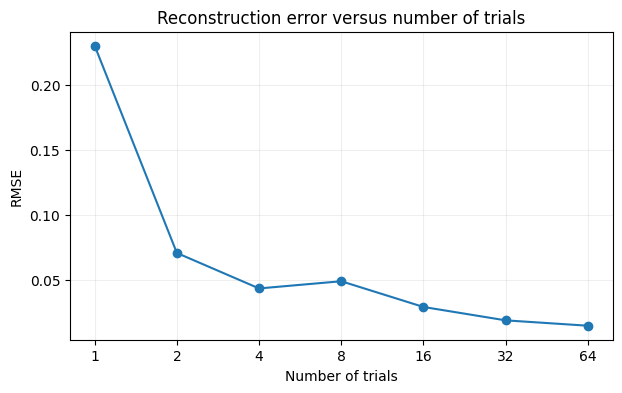

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scores["trials"], scores["rmse"], "o-")
ax.set(xlabel="Number of trials", ylabel="RMSE",
       title="Reconstruction error versus number of trials")
ax.set_xscale("log", base=2)
ax.set_xticks(trial_counts, [str(n) for n in trial_counts])
ax.grid(alpha=0.2)
plt.show()

The reconstruction error decreases as more simulated trials are combined. This checks the implementation against a known waveform; it does not show how accurately an ABR can be recovered from real EEG.

## 2. Naive deconvolution on five EEG recordings

I use `sub-exp221`–`sub-exp225` from Experiment 2 of Polonenko and Eisenreich (2026). For each recording, I select one audiobook condition, one left-ear/500 Hz pulse-train regressor, and up to 40 matched EEG trials.

The notebook needs the BrainVision recordings, event tables, and the matching HDF5 stimulus files. These data are kept outside the Git repository.

In [6]:
from pathlib import Path
import mne
from scipy.signal import butter, sosfilt, iirnotch, tf2sos
import h5py

DATA_ROOT = None  # Or Path(r"C:\OpenNeuro\ds008065")
PARTICIPANTS = [f"sub-exp22{i}" for i in range(1, 6)]
CONDITION = "wizardofoz_shifted"
MAX_TRIALS = 40
BAND_INDEX = 0
CHANNEL = "FCzA1"
FS_EEG = 10_000
PRE_SECONDS = 1
POST_SECONDS = 1
AUDIO_SECONDS = 10
EPOCH_SIZE = (PRE_SECONDS + AUDIO_SECONDS + POST_SECONDS) * FS_EEG
N_FFT = next_fast_len(EPOCH_SIZE)

if DATA_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    DATA_ROOT = next(
        (p for p in candidates if (p / "sub-exp221" / "eeg").is_dir()), None
    )
if DATA_ROOT is None:
    raise FileNotFoundError("Set DATA_ROOT to the folder containing sub-exp221 and stimuli")

DATA_ROOT = Path(DATA_ROOT)
STIM_ROOT = DATA_ROOT / "stimuli" / "exp2_f0s"
if not STIM_ROOT.is_dir():
    raise FileNotFoundError(f"Missing stimulus files: {STIM_ROOT}")

OUTPUT_DIR = Path.cwd() / "naive_results"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset:", DATA_ROOT)
print("Stimuli:", STIM_ROOT)

Dataset: c:\Users\sniki\Downloads\Caltech\Third Year\Katie's ABR project\First Week Material
Stimuli: c:\Users\sniki\Downloads\Caltech\Third Year\Katie's ABR project\First Week Material\stimuli\exp2_f0s


### Read EEG and match the pulse trains

I use `sample_corrected` from the event table for EEG onset times and the stimulus `token` to select its HDF5 file. I bandpass-filter the extracted EEG epochs and apply line-noise notches. The clock adjustment and epoch-level filtering are simplified relative to the full method in the paper.

In [ ]:
from h5io import read_hdf5
def response_window(cross_spectrum, input_power):
    full = naive_inverse(cross_spectrum, input_power, N_FFT)
    before = int(0.005 * FS_EEG)
    after = int(0.020 * FS_EEG)
    response = np.concatenate([full[-before:], full[:after]])
    time_ms = np.arange(-before, after) * 1e3 / FS_EEG
    return time_ms, response


bandpass = butter(1, [30, 2000], btype="bandpass", fs=FS_EEG, output="sos")
notches = []
for frequency in np.arange(60, 2000, 120):
    b, a = iirnotch(frequency, frequency / 5, fs=FS_EEG)
    notches.append(tf2sos(b, a))
filter_sos = np.vstack([bandpass, *notches])


def clock_adjustment(events):
    if "sample" not in events.columns:
        return 1.0
    starts = pd.to_numeric(
        events.loc[events.trial_type.eq("stimulus_start"), "sample"], errors="coerce"
    ).dropna().sort_values().to_numpy()
    ends = pd.to_numeric(
        events.loc[events.trial_type.eq("stimulus_end"), "sample"], errors="coerce"
    ).dropna().sort_values().to_numpy()
    if len(starts) == 0 or len(ends) == 0:
        return 1.0
    indices = np.searchsorted(ends, starts, side="right")
    valid = indices < len(ends)
    durations = ends[indices[valid]] - starts[valid]
    durations = durations[(durations > 8 * FS_EEG) & (durations < 11 * FS_EEG)]
    if len(durations) == 0:
        return 1.0
    return 9.98 * FS_EEG / np.median(durations)


def stimulus_file(token):
    return STIM_ROOT / CONDITION / f"{CONDITION}_{token:04d}.hdf5"


def read_stimulus(path):
    return read_hdf5(str(path), title="expyfun")


def make_pulse_train(stimulus, clock_ratio):
    key = "pulse_inds" if "pulse_inds" in stimulus else "pulseinds_true"
    indices = np.asarray(stimulus[key][BAND_INDEX], dtype=float).ravel()
    fs_audio = float(np.asarray(stimulus.get("fs", 48000)).squeeze())
    positions = np.rint((indices / fs_audio / clock_ratio + PRE_SECONDS) * FS_EEG).astype(int)
    positions = positions[(positions >= 0) & (positions < EPOCH_SIZE)]
    train = np.zeros(EPOCH_SIZE)
    train[positions] = 1
    return train

### Estimate a response for each recording

I sum the cross-spectra and pulse-train powers across the matched trials. The same unregularized `naive_inverse` function is used here as in the simulation.

In [10]:
def analyze_participant(participant):
    eeg_dir = DATA_ROOT / participant / "eeg"
    headers = sorted(eeg_dir.glob("*_eeg.vhdr"))
    if not headers:
        raise FileNotFoundError(f"No EEG headers found for {participant}")

    numerator = np.zeros(N_FFT // 2 + 1, dtype=complex)
    denominator = np.zeros(N_FFT // 2 + 1, dtype=float)
    checkpoints = {4, 8, 16, 32, MAX_TRIALS}
    estimates = {}
    used = 0
    missing_stimuli = 0

    for header in headers:
        events_path = header.with_name(header.name.replace("_eeg.vhdr", "_events.tsv"))
        if not events_path.is_file():
            raise FileNotFoundError(f"Missing event table: {events_path.name}")
        events = pd.read_csv(events_path, sep="\t")
        needed = {"trial_type", "stimulus_type", "token", "sample_corrected"}
        if not needed.issubset(events.columns):
            raise ValueError(f"Missing columns in {events_path.name}: {needed - set(events.columns)}")
        chosen = events[(events.trial_type == "stimulus_start") &
                        (events.stimulus_type == CONDITION)]
        clock_ratio = clock_adjustment(events)

        raw = mne.io.read_raw_brainvision(str(header), preload=False, verbose="ERROR")
        try:
            if int(raw.info["sfreq"]) != FS_EEG or CHANNEL not in raw.ch_names:
                raise ValueError(f"Unexpected rate or missing channel in {header.name}")

            for _, event in chosen.iterrows():
                if pd.isna(event["token"]) or pd.isna(event["sample_corrected"]):
                    continue
                token = int(event["token"])
                path = stimulus_file(token)
                if not path.is_file():
                    missing_stimuli += 1
                    continue

                onset = int(round(event["sample_corrected"])) - raw.first_samp
                start = onset - PRE_SECONDS * FS_EEG
                stop = start + EPOCH_SIZE
                if start < 0 or stop > raw.n_times:
                    continue

                eeg_trial = raw.get_data(picks=[CHANNEL], start=start, stop=stop)[0]
                eeg_trial = (eeg_trial - eeg_trial[0]) * 1e6 / 100
                eeg_trial = sosfilt(filter_sos, eeg_trial)
                pulse_train = make_pulse_train(read_stimulus(path), clock_ratio)
                if pulse_train.sum() < 10:
                    continue

                trial_X = rfft(pulse_train, n=N_FFT)
                trial_Y = rfft(eeg_trial, n=N_FFT)
                trial_Y[0] = 0
                numerator += np.conj(trial_X) * trial_Y
                denominator += np.abs(trial_X) ** 2
                used += 1
                if used in checkpoints:
                    estimates[used] = response_window(numerator, denominator)[1]
                if used >= MAX_TRIALS:
                    break
        finally:
            raw.close()
        if used >= MAX_TRIALS:
            break

    if used < 4:
        raise RuntimeError(
            f"Only {used} matched trials for {participant}; {missing_stimuli} stimulus files missing"
        )
    time_ms, response = response_window(numerator, denominator)
    estimates[used] = response
    return {"participant": participant, "trials": used, "time_ms": time_ms,
            "response": response, "estimates": estimates,
            "missing_stimuli": missing_stimuli}

In [12]:
from h5io import read_hdf5

def read_stimulus(path):
    data = read_hdf5(str(path), title="expyfun")

    while isinstance(data, dict) and list(data) == ["expyfun"]:
        data = data["expyfun"]

    return data

# Test one stimulus before processing five participants
test = read_stimulus(stimulus_file(2))
print("Available keys:", list(test))

Available keys: ['fake_pulse_inds', 'fc_band', 'fs', 'pulse_inds', 'x_play_band_chirp_CE']


In [13]:
results = []
failures = []
for participant in PARTICIPANTS:
    try:
        result = analyze_participant(participant)
        results.append(result)
        print(f"{participant}: {result['trials']} trials used")
    except (FileNotFoundError, ValueError, RuntimeError, OSError, KeyError) as error:
        failures.append({"participant": participant, "error": str(error)})
        print(f"Skipped {participant}: {error}")

if not results:
    raise RuntimeError("No estimates produced. Check the EEG and stimulus paths")

counts = pd.DataFrame([{
    "participant": r["participant"], "trials": r["trials"],
    "missing_stimulus_files": r["missing_stimuli"]
} for r in results])
display(counts)
counts.to_csv(OUTPUT_DIR / "trial_counts.csv", index=False)
if failures:
    display(pd.DataFrame(failures))

sub-exp221: 40 trials used
sub-exp222: 26 trials used
sub-exp223: 25 trials used
sub-exp224: 22 trials used
sub-exp225: 28 trials used


,participant,trials,missing_stimulus_files
0,sub-exp221,40,0
1,sub-exp222,26,184
2,sub-exp223,25,184
3,sub-exp224,22,187
4,sub-exp225,28,181


### Recovered waveforms

Each panel shows the single-band unregularized estimate for one recording. These are not ground-truth ABRs; the other speech bands and the sham/common-component subtraction have not been modeled.

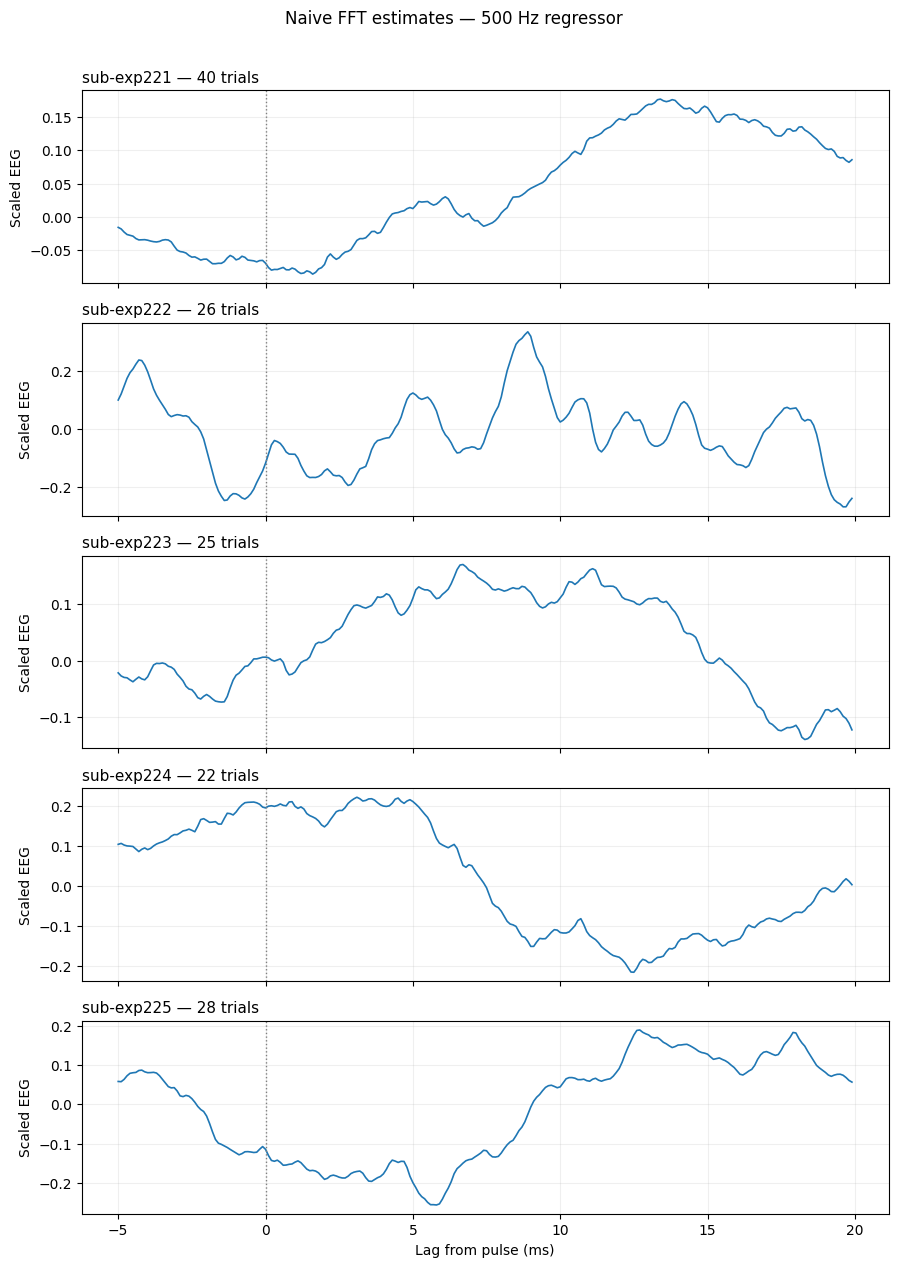

In [14]:
fig, axes = plt.subplots(len(results), 1, figsize=(9, 2.5 * len(results)),
                         sharex=True, squeeze=False)
for ax, result in zip(axes[:, 0], results):
    ax.plot(result["time_ms"], result["response"], lw=1.2)
    ax.axvline(0, color="gray", linestyle=":", lw=1)
    ax.set_title(f"{result['participant']} — {result['trials']} trials", loc="left", fontsize=11)
    ax.set_ylabel("Scaled EEG")
    ax.grid(alpha=0.2)
axes[-1, 0].set_xlabel("Lag from pulse (ms)")
fig.suptitle("Naive FFT estimates — 500 Hz regressor", y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "five_participant_naive_estimates.png", dpi=180, bbox_inches="tight")
plt.show()

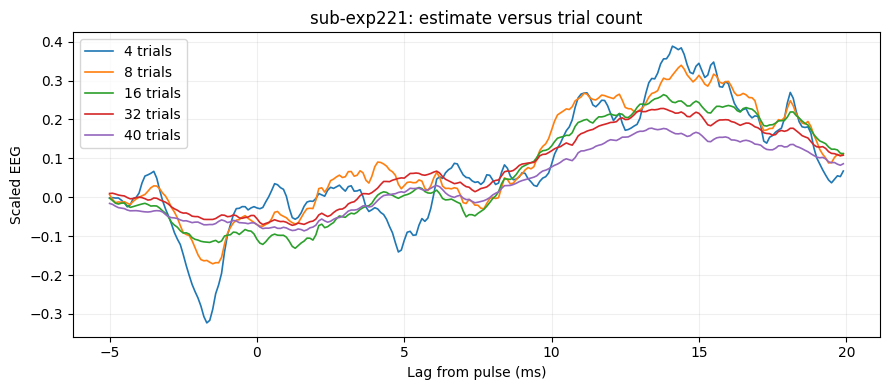

In [15]:
example = results[0]
fig, ax = plt.subplots(figsize=(9, 4))
for count in sorted(example["estimates"]):
    if count in {4, 8, 16, 32, example["trials"]}:
        ax.plot(example["time_ms"], example["estimates"][count],
                label=f"{count} trials", lw=1.2)
ax.set(xlabel="Lag from pulse (ms)", ylabel="Scaled EEG",
       title=f"{example['participant']}: estimate versus trial count")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "trial_count_comparison.png", dpi=180)
plt.show()